<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/CLIP_FashionMNIST_6_Train_4_Novel_Classes_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CLIP Lab — 6 Training Classes, 4 Unseen Classes

**Google Colab + PyTorch + OpenCLIP + Fashion-MNIST**

### One consistent split for the entire lab

| Classes allowed for mini-CLIP **training** (6) | Classes held out for **evaluation** (4) |
|---|---|
| T-shirt, Trouser, Pullover, Dress, Sandal, Sneaker | **Coat, Shirt, Bag, Ankle boot** |

The **four held-out class labels and their images are never used to train mini-CLIP**. The same four novel classes are used for the **pretrained CLIP** evaluation and **mini-CLIP** evaluation.

### Three steps, three distinct purposes

| Part | What happens? | Are weights updated? | Evaluation |
|---|---|---|---|
| **A. Pretrained CLIP demo** | Image → text and text → images | No | Similarity examples |
| **B. Pretrained CLIP, 4 novel classes** | Compare zero-shot text matching with K-shot image prototypes | No | **4-way novel-class accuracy** |
| **C. Train mini-CLIP on 6 classes** | Train a new visual transformer + new text transformer jointly | **Yes: both** | **4-way novel-class zero-shot and K-shot accuracy** |

**One caption template throughout the Fashion-MNIST experiments:** `a photo of {class}`.

- **Zero-shot (K = 0):** classify a new image by comparing its embedding with four class-name **text embeddings**. No labeled image from the four novel classes is supplied.
- **Few-shot (K = 1, 2, 5, 10, 20):** choose K labeled novel-class images per class from the **Fashion-MNIST training split** to build four visual prototypes. Evaluate on separate images from the **Fashion-MNIST test split**. **No gradient updates** during few-shot testing.
- **Important limitation:** Mini-CLIP's text encoder is initialized randomly and only trained on six class captions. It has not learned the meanings of the four held-out class names. Its novel-class zero-shot accuracy may be low; this is a useful lesson about the limits of training CLIP on only six captions. Mini-CLIP's **few-shot** test instead examines whether its visual embeddings transfer.

**Reference:** [Correll Lab — *Building CLIP From Scratch*](https://medium.com/correll-lab/building-clip-from-scratch-68f6e42d35f4). This teaching implementation follows the two-encoder architecture and symmetric contrastive loss with simpler, class-balanced batches.

## 0 — Setup

Install OpenCLIP, then load OpenAI's pretrained CLIP ViT-B/32. CLIP has an image encoder $f_\theta$ and a text encoder $g_\phi$. We normalize their embeddings so that the dot product equals cosine similarity:

$$z_I = \frac{f_\theta(x)}{\|f_\theta(x)\|_2},\qquad z_T = \frac{g_\phi(t)}{\|g_\phi(t)\|_2},\qquad s(x,t) = z_I^\top z_T.$$

OpenCLIP documentation: https://github.com/mlfoundations/open_clip

In [ ]:
%pip -q install open_clip_torch

In [ ]:
import copy
import io
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import FashionMNIST
import open_clip

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
FAST_CPU = DEVICE.type == 'cpu'
print('Device:', DEVICE, '| Smaller CPU dataset:', FAST_CPU)

# The quickgelu variant matches the activation used by OpenAI CLIP weights.
MODEL_NAME = 'ViT-B-32-quickgelu'
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME, pretrained='openai'
)
clip_model = clip_model.to(DEVICE).eval()
for p in clip_model.parameters():
    p.requires_grad_(False)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
print('CLIP image embedding size:', clip_model.visual.output_dim)

Device: cuda | Smaller CPU dataset: False


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP image embedding size: 512


# Part A — Explore pretrained CLIP (no training)

**A1. Image → text.** Give CLIP one image and several text descriptions. CLIP computes a similarity score for each description. Softmax turns the *candidate-relative* scores into values summing to 1. They are not calibrated probabilities of arbitrary real-world statements.

We try to load a natural dog photo for this demo (with a Fashion-MNIST fallback if the download is blocked).

In [ ]:
train_ds = FashionMNIST(root='./data', train=True, download=True)
test_ds = FashionMNIST(root='./data', train=False, download=True)
CLASS_NAMES = [
    't-shirt', 'trousers', 'pullover sweater', 'dress', 'coat',
    'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot'
]
print('Fashion-MNIST:', len(train_ds), 'train /', len(test_ds), 'test images')

Fashion-MNIST: 60000 train / 10000 test images


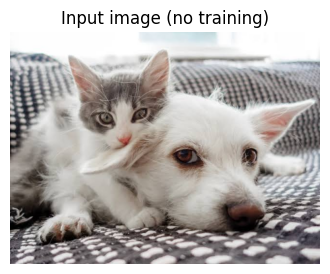

In [ ]:
def get_demo_image():
    url = 'https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg'
    url = 'https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRp77f0yVBzCBW85nyzU7zs6_Ml3qQMLDhk0xwOlVg_Iy6dHlqg28w2SqV-&s=10'
    try:
        with urllib.request.urlopen(url, timeout=12) as res:
            return Image.open(io.BytesIO(res.read())).convert('RGB'), 'dog'
    except Exception as exc:
        print('Natural image unavailable; using Fashion-MNIST instead:', type(exc).__name__)
        ix = int(np.where(np.array(train_ds.targets) == 7)[0][0])
        return train_ds[ix][0].convert('RGB'), 'sneaker'

demo_image, demo_type = get_demo_image()
plt.figure(figsize=(4, 4))
plt.imshow(demo_image)
plt.title('Input image (no training)')
plt.axis('off')
plt.show()

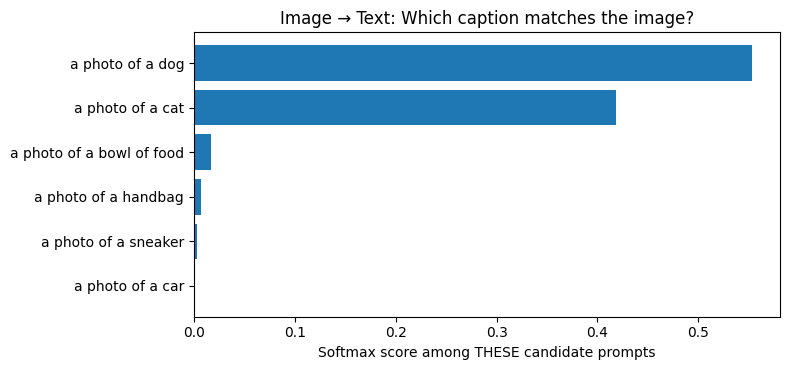

Most similar caption: a photo of a dog


In [ ]:
# Student exercise: edit one of these prompts and run again.
TEXT_PROMPTS = [
    'a photo of a dog',
    'a photo of a cat',
    'a photo of a sneaker',
    'a photo of a car',
    'a photo of a handbag',
    'a photo of a bowl of food'
]

with torch.inference_mode():
    image_tensor = preprocess(demo_image).unsqueeze(0).to(DEVICE)
    text_tokens = tokenizer(TEXT_PROMPTS).to(DEVICE)
    image_features = F.normalize(clip_model.encode_image(image_tensor).float(), dim=-1)
    text_features = F.normalize(clip_model.encode_text(text_tokens).float(), dim=-1)
    cosine_scores = (image_features @ text_features.T).squeeze(0)
    # CLIP's original inference examples commonly use 100 * similarity.
    relative_scores = (100.0 * cosine_scores).softmax(dim=-1).cpu().numpy()

order = np.argsort(-relative_scores)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(np.array(TEXT_PROMPTS)[order][::-1], relative_scores[order][::-1])
ax.set_xlabel('Softmax score among THESE candidate prompts')
ax.set_title('Image → Text: Which caption matches the image?')
plt.tight_layout()
plt.show()
print('Most similar caption:', TEXT_PROMPTS[int(order[0])])

---
# Part B — Frozen pretrained CLIP: 4 unseen Fashion-MNIST classes

Pretrained CLIP already learned image–language alignment on external data. **We do not fine-tune it**. First establish the strict class split and inspect actual example images. All accuracy results in Parts B and C are evaluated on exactly the same **four classes** and **query images**.

In [ ]:
# THE SINGLE SOURCE OF TRUTH: do not change the split elsewhere.
TRAIN_CLASSES = [0, 1, 2, 3, 5, 7]  # t-shirt, trousers, pullover, dress, sandal, sneaker
NOVEL_CLASSES = [4, 6, 8, 9]        # coat, shirt, bag, ankle boot
assert len(TRAIN_CLASSES) == 6 and len(NOVEL_CLASSES) == 4
assert sorted(TRAIN_CLASSES + NOVEL_CLASSES) == list(range(10))
assert set(TRAIN_CLASSES).isdisjoint(NOVEL_CLASSES)

TRAIN_CLASS_NAMES = [CLASS_NAMES[c] for c in TRAIN_CLASSES]
NOVEL_CLASS_NAMES = [CLASS_NAMES[c] for c in NOVEL_CLASSES]
CLASS_PROMPTS = [f'a photo of {name}' for name in CLASS_NAMES]
NOVEL_PROMPTS = [CLASS_PROMPTS[c] for c in NOVEL_CLASSES]

SHOTS = [1, 2, 5, 10, 20]
SUPPORT_POOL_PER_CLASS = max(SHOTS)
QUERY_PER_CLASS = 60 if not FAST_CPU else 12
REPEATS = 5

print('6 TRAINED class names:', TRAIN_CLASS_NAMES)
print('4 HELD-OUT class names:', NOVEL_CLASS_NAMES)
print('ONLY prompt format:', NOVEL_PROMPTS)
print('4-way random-guess baseline: 25%')

6 TRAINED class names: ['t-shirt', 'trousers', 'pullover sweater', 'dress', 'sandal', 'sneaker']
4 HELD-OUT class names: ['coat', 'shirt', 'bag', 'ankle boot']
ONLY prompt format: ['a photo of coat', 'a photo of shirt', 'a photo of bag', 'a photo of ankle boot']
4-way random-guess baseline: 25%


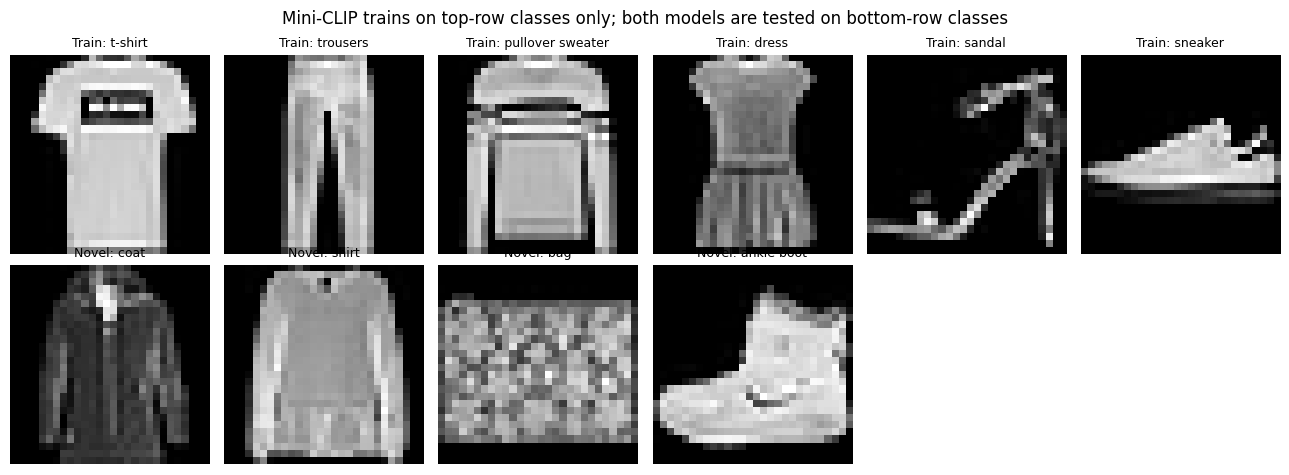

In [ ]:
# Visual proof of the split: these are Fashion-MNIST TRAIN images.
labels_np = np.asarray(train_ds.targets)
fig, axs = plt.subplots(2, 6, figsize=(13, 4.8))
for ax in axs.ravel():
    ax.axis('off')
for j, c in enumerate(TRAIN_CLASSES):
    idx = int(np.flatnonzero(labels_np == c)[0])
    axs[0, j].imshow(train_ds[idx][0], cmap='gray')
    axs[0, j].set_title(f'Train: {CLASS_NAMES[c]}', fontsize=9)
for j, c in enumerate(NOVEL_CLASSES):
    idx = int(np.flatnonzero(labels_np == c)[0])
    axs[1, j].imshow(train_ds[idx][0], cmap='gray')
    axs[1, j].set_title(f'Novel: {CLASS_NAMES[c]}', fontsize=9)
plt.suptitle('Mini-CLIP trains on top-row classes only; both models are tested on bottom-row classes', fontsize=12)
plt.tight_layout()
plt.show()

## B1 — Select 4-way support and query images

**Support:** novel-class labeled images from the original Fashion-MNIST **training** split. Used **only to form prototypes at evaluation time**; never used to train mini-CLIP.

**Query:** novel-class images from the official Fashion-MNIST **test** split. Never used as support or for model training.

We randomly sample a fixed number of query images per class so all comparisons use the same evaluation set.

In [ ]:
def choose_indices(ds, class_ids, n_per_class, seed):
    rng = np.random.default_rng(seed)
    labels = np.asarray(ds.targets)
    chosen = []
    for c in class_ids:
        eligible = np.flatnonzero(labels == c)
        chosen.extend(rng.choice(eligible, size=n_per_class, replace=False).tolist())
    return chosen

support_indices = choose_indices(train_ds, NOVEL_CLASSES, SUPPORT_POOL_PER_CLASS, SEED)
query_indices = choose_indices(test_ds, NOVEL_CLASSES, QUERY_PER_CLASS, SEED + 1)

assert set(np.asarray(train_ds.targets)[support_indices]) == set(NOVEL_CLASSES)
assert set(np.asarray(test_ds.targets)[query_indices]) == set(NOVEL_CLASSES)
print('Novel classes:', NOVEL_CLASS_NAMES)
print('Support:', len(support_indices), 'labeled images from TRAIN split')
print('Query:', len(query_indices), 'unseen images from TEST split')
print('Each K-shot draw uses', '4 × K', 'labeled support images (K per class).')

Novel classes: ['coat', 'shirt', 'bag', 'ankle boot']
Support: 80 labeled images from TRAIN split
Query: 240 unseen images from TEST split
Each K-shot draw uses 4 × K labeled support images (K per class).


## B2 — Visual example: what is 5-shot?

For **5-shot 4-way classification**, we provide five labeled images for **each** of the four novel classes: $4\times 5=20$ support images. CLIP weights stay frozen.

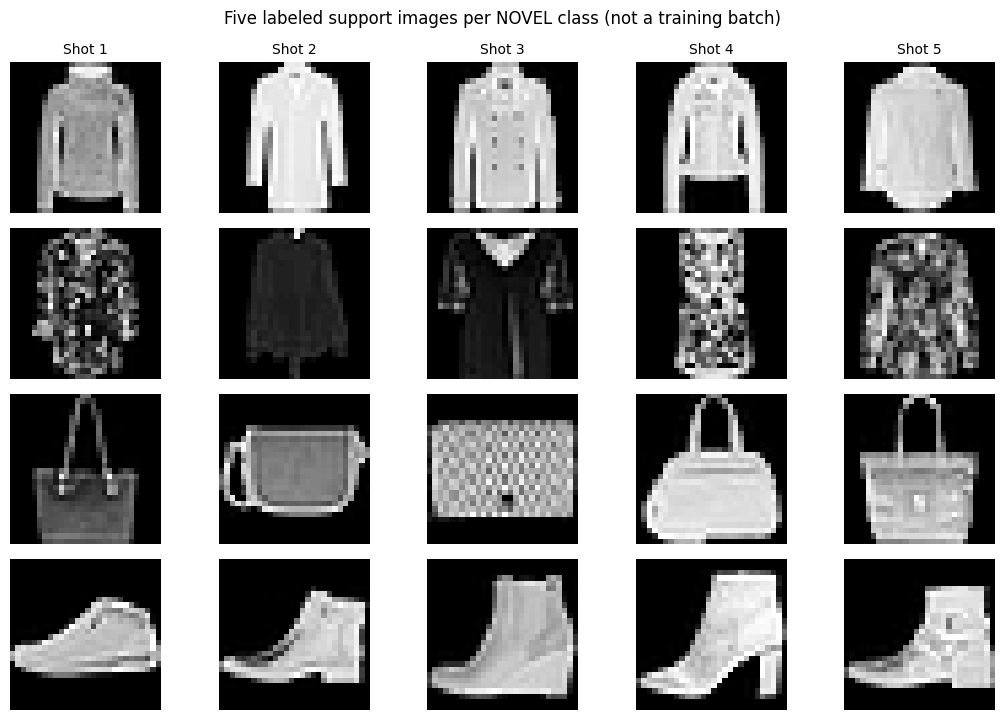

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(10.8, 7.3))
for row, c in enumerate(NOVEL_CLASSES):
    eligible = [i for i in support_indices if int(train_ds.targets[i]) == c]
    for col, idx in enumerate(eligible[:5]):
        axes[row, col].imshow(train_ds[idx][0], cmap='gray')
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(CLASS_NAMES[c], rotation=0, labelpad=48, va='center', fontsize=10)
        if row == 0:
            axes[row, col].set_title(f'Shot {col+1}', fontsize=10)
plt.suptitle('Five labeled support images per NOVEL class (not a training batch)', fontsize=12)
plt.tight_layout()
plt.show()

## B3 — Extract frozen pretrained CLIP image embeddings

CLIP requires RGB images of its expected size; its normal image preprocessing handles the grayscale-to-RGB conversion and resize. We extract embeddings **once**, then do all K-shot trials using vectors without rerunning the encoder.

In [ ]:
class CLIPImageSubset(Dataset):
    def __init__(self, dataset, indices):
        self.dataset = dataset
        self.indices = list(indices)
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, ix):
        image, label = self.dataset[self.indices[ix]]
        return preprocess(image.convert('RGB')), label

@torch.inference_mode()
def frozen_clip_embeddings(dataset, indices):
    loader = DataLoader(CLIPImageSubset(dataset, indices),
                        batch_size=(32 if not FAST_CPU else 8), shuffle=False, num_workers=0)
    xs, ys = [], []
    clip_model.eval()
    for images, labels in loader:
        features = clip_model.encode_image(images.to(DEVICE))
        xs.append(F.normalize(features.float(), dim=-1).cpu())
        ys.append(labels.long())
    return torch.cat(xs), torch.cat(ys)

support_embeddings, support_labels = frozen_clip_embeddings(train_ds, support_indices)
query_embeddings, query_labels = frozen_clip_embeddings(test_ds, query_indices)
print('Support embeddings:', tuple(support_embeddings.shape))
print('Test embeddings:', tuple(query_embeddings.shape))
assert not any(p.requires_grad for p in clip_model.parameters())

Support embeddings: (80, 512)
Test embeddings: (240, 512)


## B4 — Pretrained CLIP ZERO-shot (4 novel classes)

Use only four text prompts: `a photo of coat`, `a photo of shirt`, `a photo of bag`, `a photo of ankle boot`. For each query image, select the closest **text embedding**. No labeled support images are involved.

In [ ]:
with torch.inference_mode():
    novel_text_tokens = tokenizer(NOVEL_PROMPTS).to(DEVICE)
    pretrained_text_z = F.normalize(clip_model.encode_text(novel_text_tokens).float(), dim=-1).cpu()

pretrained_zero_scores = query_embeddings @ pretrained_text_z.T
pretrained_zero_local_pred = pretrained_zero_scores.argmax(dim=1)
pretrained_zero_pred = torch.tensor(NOVEL_CLASSES)[pretrained_zero_local_pred]
pretrained_zero_acc = (pretrained_zero_pred == query_labels).float().mean().item() * 100
print(f'Pretrained CLIP | 4-way NOVEL-class ZERO-shot: {pretrained_zero_acc:.2f}%')
print('Chance level: 25%.  No Fashion-MNIST training / no novel-class support examples.')

Pretrained CLIP | 4-way NOVEL-class ZERO-shot: 79.17%
Chance level: 25%.  No Fashion-MNIST training / no novel-class support examples.


## B5 — Pretrained CLIP FEW-shot (4 novel classes)

Use K novel-class labeled images to make **one average visual prototype per class**. The text encoder is **not** used for the K-shot visual-prototype prediction. All parameters remain frozen:

$$\mu_c = \operatorname{normalize}\left(\frac{1}{K}\sum_{i \in S_c} z_i\right), \qquad
\hat y = \underset{c}{\arg\max}\; z_q^\top\mu_c.$$

Each row below aggregates **five independently drawn support sets**, always with the same held-out test queries.

Pretrained CLIP ZERO-shot: 79.17%
Pretrained CLIP FEW-shot, mean ± std over support draws:


,Shots/class,mean,std
0,1,66.42,5.47
1,2,71.58,4.66
2,5,73.75,3.63
3,10,77.25,2.26
4,20,78.75,0.00


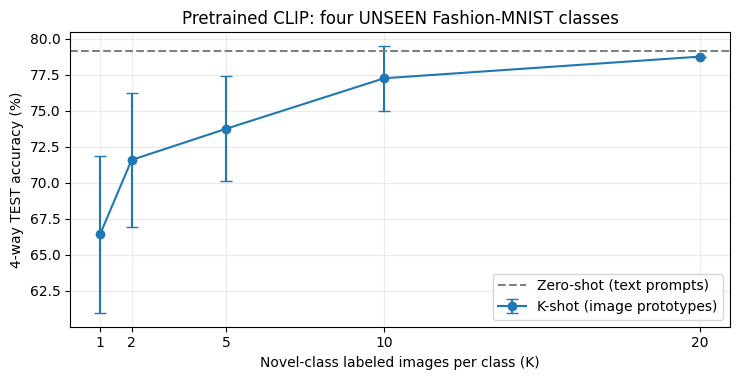

In [ ]:
def predict_visual_prototypes(support_x, support_y, test_x, class_ids, k, seed):
    # Works for BOTH pretrained CLIP and scratch mini-CLIP image embeddings.
    rng = np.random.default_rng(seed)
    labels_np = support_y.numpy()
    prototypes = []
    for c in class_ids:
        eligible = np.flatnonzero(labels_np == c)
        chosen = rng.choice(eligible, size=k, replace=False)
        prototypes.append(F.normalize(support_x[chosen].mean(dim=0), dim=0))
    prototypes = torch.stack(prototypes)
    scores = test_x @ prototypes.T
    predictions = torch.tensor(class_ids, dtype=torch.long)[scores.argmax(dim=1)]
    return predictions, scores


def evaluate_few_shot(model_name, support_x, support_y, test_x, test_y):
    rows = []
    for k in SHOTS:
        for repeat in range(REPEATS):
            pred, _ = predict_visual_prototypes(
                support_x, support_y, test_x, NOVEL_CLASSES, k, seed=100 + repeat
            )
            rows.append({
                'Model': model_name, 'Shots/class': k, 'Support draw': repeat + 1,
                'Accuracy (%)': (pred == test_y).float().mean().item() * 100,
            })
    return pd.DataFrame(rows)

pretrained_fewshot_df = evaluate_few_shot(
    'Pretrained CLIP', support_embeddings, support_labels, query_embeddings, query_labels
)
pretrained_summary = (pretrained_fewshot_df.groupby('Shots/class')['Accuracy (%)']
                      .agg(['mean', 'std']).reset_index())
print(f'Pretrained CLIP ZERO-shot: {pretrained_zero_acc:.2f}%')
print('Pretrained CLIP FEW-shot, mean ± std over support draws:')
display(pretrained_summary.round(2))

plt.figure(figsize=(7.5, 3.9))
plt.errorbar(pretrained_summary['Shots/class'], pretrained_summary['mean'],
             yerr=pretrained_summary['std'], capsize=4, marker='o', label='K-shot (image prototypes)')
plt.axhline(pretrained_zero_acc, color='gray', linestyle='--', label='Zero-shot (text prompts)')
plt.xticks(SHOTS); plt.xlabel('Novel-class labeled images per class (K)')
plt.ylabel('4-way TEST accuracy (%)'); plt.title('Pretrained CLIP: four UNSEEN Fashion-MNIST classes')
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

## B6 — See real novel-class query predictions

Each image comes from the **Fashion-MNIST test split**. Compare zero-shot text predictions with 5-shot visual-prototype predictions; both use the same frozen image encoder.

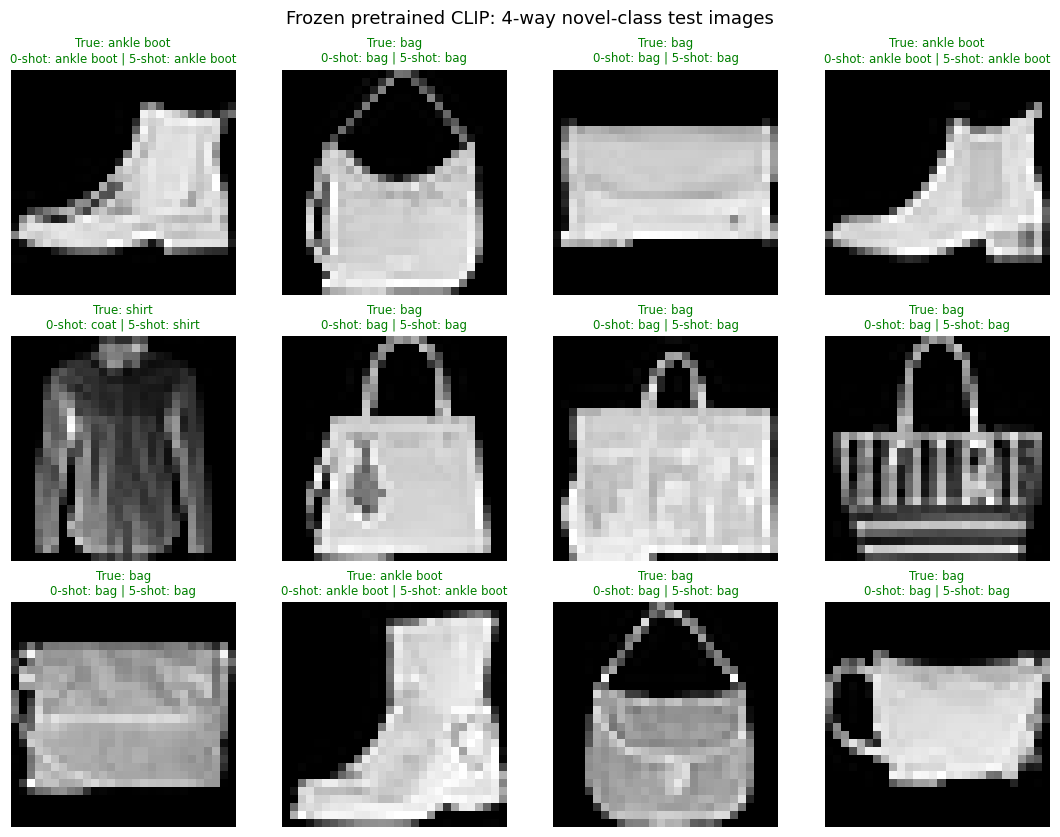

In [ ]:
pretrained_5shot_pred, _ = predict_visual_prototypes(
    support_embeddings, support_labels, query_embeddings, NOVEL_CLASSES, k=5, seed=100
)
show_pos = np.random.default_rng(SEED+3).choice(len(query_indices), size=12, replace=False)
fig, axs = plt.subplots(3, 4, figsize=(11, 8.5))
for ax, pos in zip(axs.ravel(), show_pos):
    truth = int(query_labels[pos]); z = int(pretrained_zero_pred[pos]); f = int(pretrained_5shot_pred[pos])
    ax.imshow(test_ds[query_indices[int(pos)]][0], cmap='gray')
    ax.set_title(f'True: {CLASS_NAMES[truth]}\n0-shot: {CLASS_NAMES[z]} | 5-shot: {CLASS_NAMES[f]}',
                 fontsize=8.5, color='green' if f == truth else 'crimson')
    ax.axis('off')
plt.suptitle('Frozen pretrained CLIP: 4-way novel-class test images', fontsize=13)
plt.tight_layout(); plt.show()

---
# Part C — Train mini-CLIP from scratch on ONLY 6 classes

**This is a new model, unrelated to pretrained CLIP's weights.** Its image transformer and text transformer both start from random initialization.

**Training images:** Fashion-MNIST *training* images of the **six TRAIN_CLASSES only**.  
**Training captions:** `a photo of {class}` for **only those six classes**.  
**Evaluation:** image and text matching on the four held-out classes from Part B, with the **same queries and support sets**.

> **Important scientific caveat:** True general-purpose open-vocabulary zero-shot performance needs rich image–text training. Six class captions cannot teach a new language encoder what unseen clothing names mean. We still report mini-CLIP **4-way held-out-class zero-shot** for teaching, but **do not expect it to compete fairly with large-scale pretrained CLIP**. Its K-shot image-prototype scores are a complementary test of visual-feature transfer.

## C1 — Two small transformer encoders, trainable from scratch

- **Image encoder:** 28×28 grayscale image → 16 image patches → Transformer → normalized 64-dimensional feature.
- **Text encoder:** characters of `a photo of {class}` → Transformer → normalized 64-dimensional feature.

We deliberately use a **character tokenizer** rather than a six-class word vocabulary. This avoids mapping all four unseen class names to the same `<unknown>` token. It **does not** give a randomly initialized text encoder any pretrained language understanding.

In [ ]:
# Mini-CLIP trains on SIX captions only. No novel-class caption is used here.
TRAIN_CAPTIONS = [CLASS_PROMPTS[c] for c in TRAIN_CLASSES]

PAD, BOS, EOS = '<pad>', '<bos>', '<eos>'
# A FIXED ASCII letter-level alphabet, unrelated to train/novel split.
# Characters can be represented, but this DOES NOT teach their meanings.
ALPHABET = list('abcdefghijklmnopqrstuvwxyz -')
VOCAB = {PAD: 0, BOS: 1, EOS: 2}
VOCAB.update({ch: i + 3 for i, ch in enumerate(ALPHABET)})
SEQ_LEN = 32

def encode_caption(s):
    chars = [BOS] + list(s.lower()) + [EOS]
    ids = [VOCAB[ch] for ch in chars]
    assert len(ids) <= SEQ_LEN
    return ids + [VOCAB[PAD]] * (SEQ_LEN - len(ids))

train_caption_tokens = torch.tensor([encode_caption(s) for s in TRAIN_CAPTIONS], dtype=torch.long)
print('Scratch TRAIN captions (6):', TRAIN_CAPTIONS)
print('Training caption tokens:', tuple(train_caption_tokens.shape))
print('No novel captions are tokenized or passed to mini-CLIP during training.')

Scratch TRAIN captions (6): ['a photo of t-shirt', 'a photo of trousers', 'a photo of pullover sweater', 'a photo of dress', 'a photo of sandal', 'a photo of sneaker']
Training caption tokens: (6, 32)
No novel captions are tokenized or passed to mini-CLIP during training.


In [ ]:
class TinyImageEncoder(nn.Module):
    def __init__(self, width=64, embed_dim=64):
        super().__init__()
        self.patches = nn.Conv2d(1, width, kernel_size=7, stride=7)  # 28 -> 4x4 = 16 patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, width))
        self.positions = nn.Parameter(torch.randn(1, 17, width) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=width, nhead=4, dim_feedforward=128,
                                           dropout=0.0, batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(width)
        self.projection = nn.Linear(width, embed_dim)

    def forward(self, images):
        x = self.patches(images).flatten(2).transpose(1, 2)   # [B, 16, 64]
        cls = self.cls_token.expand(images.shape[0], -1, -1)
        x = torch.cat([cls, x], dim=1) + self.positions         # [B, 17, 64]
        x = self.transformer(x)
        return F.normalize(self.projection(self.norm(x[:, 0])), dim=-1)


class TinyTextEncoder(nn.Module):
    def __init__(self, vocab_size, width=64, embed_dim=64):
        super().__init__()
        self.word_embedding = nn.Embedding(vocab_size, width, padding_idx=VOCAB[PAD])
        self.positions = nn.Parameter(torch.randn(1, SEQ_LEN, width) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=width, nhead=4, dim_feedforward=128,
                                           dropout=0.0, batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(width)
        self.projection = nn.Linear(width, embed_dim)

    def forward(self, tokens):
        x = self.word_embedding(tokens) + self.positions
        x = self.transformer(x, src_key_padding_mask=(tokens == VOCAB[PAD]))
        return F.normalize(self.projection(self.norm(x[:, 0])), dim=-1)  # BOS token as summary


class MiniCLIP(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.image_encoder = TinyImageEncoder()
        self.text_encoder = TinyTextEncoder(vocab_size)
        # CLIP uses a learnable logit scale (inverse temperature).
        self.logit_scale = nn.Parameter(torch.tensor(np.log(1 / 0.07), dtype=torch.float32))

    def forward(self, images, tokens):
        image_z = self.image_encoder(images)
        text_z = self.text_encoder(tokens)
        similarity = image_z @ text_z.T
        logits = similarity * self.logit_scale.exp().clamp(max=100)
        return logits, image_z, text_z


scratch_model = MiniCLIP(len(VOCAB)).to(DEVICE)
print('Newly initialized mini-CLIP:', f'{sum(p.numel() for p in scratch_model.parameters()):,}', 'parameters')
print('Image encoder trainable:', any(p.requires_grad for p in scratch_model.image_encoder.parameters()))
print('Text encoder trainable:', any(p.requires_grad for p in scratch_model.text_encoder.parameters()))

Newly initialized mini-CLIP: 117,377 parameters
Image encoder trainable: True
Text encoder trainable: True


## C2 — The 6×6 contrastive loss

Fashion-MNIST provides repeated *class captions*, not unique rich captions for every image. Ordinary CLIP loss treats other image–text positions in the batch as negatives, which would make identical class captions incorrectly compete.

**Our simple solution:** each training step uses exactly **one image per each of the six training classes**, paired with its unique caption. The positive pairs are the six diagonal cells of a **6×6 similarity matrix**.

$$\mathcal L = \tfrac{1}{2}\big[\operatorname{CE}(S, \text{diagonal labels}) + \operatorname{CE}(S^\top, \text{diagonal labels})\big].$$

Calling `loss.backward()` calculates gradients for **both** encoders at the current parameter state. `optimizer.step()` then updates both weights together.

In [ ]:
def symmetric_clip_loss(logits):
    targets = torch.arange(logits.shape[0], device=logits.device)
    return 0.5 * (F.cross_entropy(logits, targets) + F.cross_entropy(logits.T, targets))

with torch.no_grad():
    dummy_images = torch.randn(len(TRAIN_CLASSES), 1, 28, 28, device=DEVICE)
    logits, image_z, text_z = scratch_model(dummy_images, train_caption_tokens.to(DEVICE))
print('Six image embeddings:', tuple(image_z.shape))
print('Six text embeddings:', tuple(text_z.shape))
print('Similarity matrix:', tuple(logits.shape), '— diagonals represent matching pairs.')
assert logits.shape == (6, 6)

Six image embeddings: (6, 64)
Six text embeddings: (6, 64)
Similarity matrix: (6, 6) — diagonals represent matching pairs.


## C3 — Prepare ONLY the six training classes

We take a small number of Fashion-MNIST *training* images from each of the six allowed classes. No Coat, Shirt, Bag, or Ankle boot image is ever used during mini-CLIP training.

In [ ]:
TRAIN_IMAGES_PER_CLASS = 280 if DEVICE.type == 'cuda' else 36
EPOCHS = 7 if DEVICE.type == 'cuda' else 2
LR = 6e-4

train_np_labels = np.asarray(train_ds.targets)
index_rng = np.random.default_rng(SEED + 7)
class_image_pools = []
training_image_indices = []
for c in TRAIN_CLASSES:
    eligible = np.flatnonzero(train_np_labels == c)
    chosen = index_rng.choice(eligible, size=TRAIN_IMAGES_PER_CLASS, replace=False)
    training_image_indices.extend(chosen.tolist())
    class_image_pools.append(train_ds.data[chosen].unsqueeze(1).float() / 255.0)
class_image_pools = torch.stack(class_image_pools)   # [6, N, 1, 28, 28]

assert set(train_np_labels[training_image_indices]) == set(TRAIN_CLASSES)
assert not (set(train_np_labels[training_image_indices]) & set(NOVEL_CLASSES))
assert set(training_image_indices).isdisjoint(support_indices)
print('Training tensor:', tuple(class_image_pools.shape))
print('Only trained classes:', TRAIN_CLASS_NAMES)
print('Each batch: 6 images + 6 UNIQUE matching captions')
print('Steps / epoch:', TRAIN_IMAGES_PER_CLASS, '| epochs:', EPOCHS)

Training tensor: (6, 280, 1, 28, 28)
Only trained classes: ['t-shirt', 'trousers', 'pullover sweater', 'dress', 'sandal', 'sneaker']
Each batch: 6 images + 6 UNIQUE matching captions
Steps / epoch: 280 | epochs: 7


In [ ]:
# A fixed 6-image training example lets students compare similarity before/after learning.
scratch_fixed_images = class_image_pools[:, 0].to(DEVICE)

@torch.inference_mode()
def scratch_similarity_six():
    was_training = scratch_model.training
    scratch_model.eval()
    a = scratch_model.image_encoder(scratch_fixed_images)
    b = scratch_model.text_encoder(train_caption_tokens.to(DEVICE))
    sim = (a @ b.T).cpu().numpy()
    if was_training:
        scratch_model.train()
    return sim

similarity_before = scratch_similarity_six()
print('Saved mini-CLIP similarity matrix BEFORE training: 6 × 6')

Saved mini-CLIP similarity matrix BEFORE training: 6 × 6


## C4 — Train BOTH mini-CLIP encoders

Every training batch uses six distinct training class labels. This is **not few-shot learning**—it is ordinary supervised image–text contrastive learning on the six training classes.

Epoch 01/7 | loss=0.809 | 6-class train matching=66.4%
Epoch 02/7 | loss=0.304 | 6-class train matching=87.3%
Epoch 03/7 | loss=0.246 | 6-class train matching=88.8%
Epoch 04/7 | loss=0.188 | 6-class train matching=90.9%
Epoch 05/7 | loss=0.171 | 6-class train matching=91.9%
Epoch 06/7 | loss=0.140 | 6-class train matching=92.7%
Epoch 07/7 | loss=0.140 | 6-class train matching=93.2%


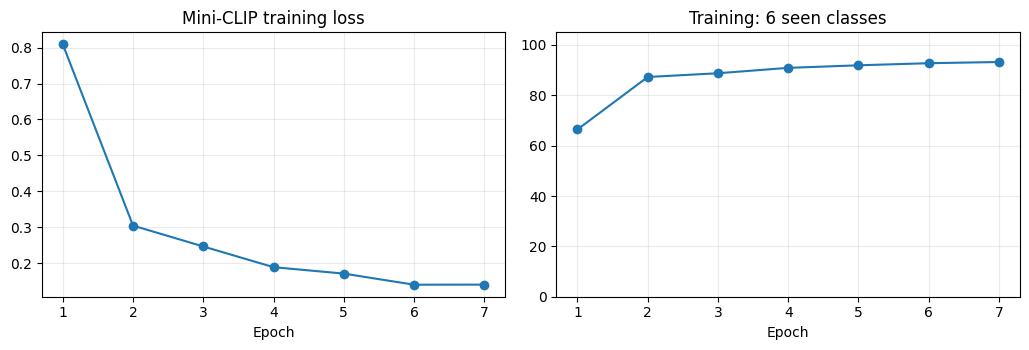

In [ ]:
optimizer = torch.optim.AdamW(scratch_model.parameters(), lr=LR, weight_decay=1e-4)
train_history = []
scratch_model.train()

for epoch in range(EPOCHS):
    per_class_order = [torch.randperm(TRAIN_IMAGES_PER_CLASS) for _ in TRAIN_CLASSES]
    running_loss = running_acc = 0.0
    for step in range(TRAIN_IMAGES_PER_CLASS):
        # One training image per class, in TRAIN_CLASSES order.
        images = torch.stack([
            class_image_pools[j, per_class_order[j][step]]
            for j in range(len(TRAIN_CLASSES))
        ]).to(DEVICE)
        order = torch.randperm(len(TRAIN_CLASSES))
        images = images[order.to(DEVICE)]
        tokens = train_caption_tokens[order].to(DEVICE)

        optimizer.zero_grad()
        logits, _, _ = scratch_model(images, tokens)
        loss = symmetric_clip_loss(logits)
        loss.backward()   # Gradients for BOTH image and text transformers.
        optimizer.step()  # BOTH are updated (not alternating).

        running_loss += loss.item()
        running_acc += (logits.argmax(dim=1) == torch.arange(6, device=DEVICE)).float().mean().item()

    history_row = {
        'Epoch': epoch + 1,
        'Contrastive loss': running_loss / TRAIN_IMAGES_PER_CLASS,
        'Image→text match accuracy (%)': 100 * running_acc / TRAIN_IMAGES_PER_CLASS,
    }
    train_history.append(history_row)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"loss={history_row['Contrastive loss']:.3f} | "
          f"6-class train matching={history_row['Image→text match accuracy (%)']:.1f}%")

scratch_model.eval()
training_log = pd.DataFrame(train_history)
fig, axs = plt.subplots(1, 2, figsize=(10.4, 3.6))
axs[0].plot(training_log['Epoch'], training_log['Contrastive loss'], marker='o')
axs[0].set_title('Mini-CLIP training loss')
axs[1].plot(training_log['Epoch'], training_log['Image→text match accuracy (%)'], marker='o')
axs[1].set_title('Training: 6 seen classes'); axs[1].set_ylim(0, 105)
for ax in axs: ax.set_xlabel('Epoch'); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## C5 — Visualize CLIP learning: six training classes

The heatmaps compare the **same six training images** and **six captions** before versus after training. A bright diagonal after training means the correct image–caption pairs have learned to align.

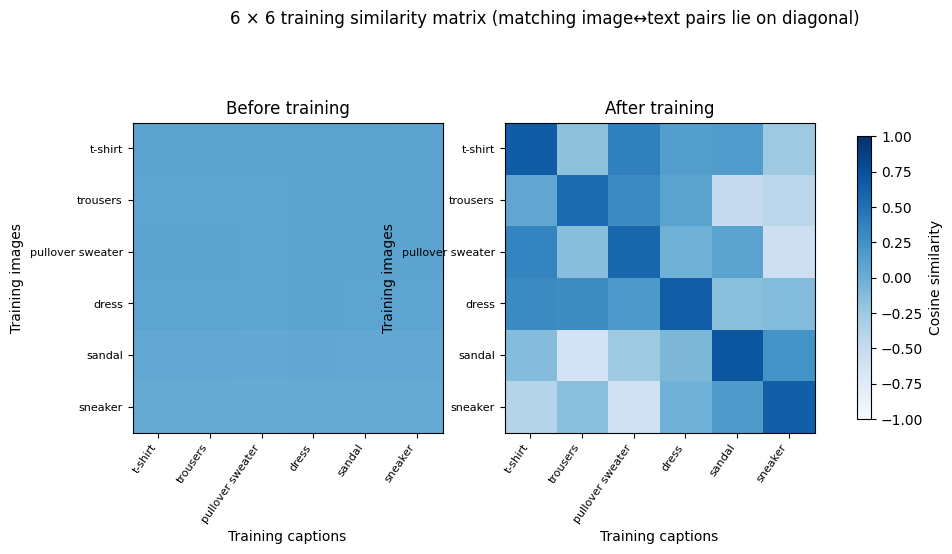

In [ ]:
similarity_after = scratch_similarity_six()
fig, axs = plt.subplots(1, 2, figsize=(11, 5.1))
for ax, mat, title in zip(axs, [similarity_before, similarity_after],
                          ['Before training', 'After training']):
    im = ax.imshow(mat, cmap='Blues', vmin=-1, vmax=1)
    ax.set_xticks(range(6)); ax.set_yticks(range(6))
    ax.set_xticklabels(TRAIN_CLASS_NAMES, rotation=55, ha='right', fontsize=8)
    ax.set_yticklabels(TRAIN_CLASS_NAMES, fontsize=8)
    ax.set_xlabel('Training captions'); ax.set_ylabel('Training images')
    ax.set_title(title)
fig.colorbar(im, ax=axs, shrink=.72, label='Cosine similarity')
plt.suptitle('6 × 6 training similarity matrix (matching image↔text pairs lie on diagonal)', y=1.02)
plt.show()

## C6 — Mini-CLIP ZERO-shot: the SAME four unseen classes

**No novel-class support images in this experiment.** The scratch image encoder processes the exact same queries as pretrained CLIP. The randomly initialized (but six-class-trained) text encoder embeds exactly the same four `a photo of {class}` prompts.

Be cautious: because mini-CLIP never learned the novel class-name semantics, **this score could be near chance**. That is a property of the strict small-data setup—not evidence that contrastive learning does not work.

In [ ]:
@torch.inference_mode()
def scratch_image_embeddings(ds, indices, batch_size=128):
    scratch_model.eval()
    xs, ys = [], []
    for start in range(0, len(indices), batch_size):
        idx = indices[start:start + batch_size]
        images = ds.data[idx].unsqueeze(1).float().to(DEVICE) / 255.0
        xs.append(scratch_model.image_encoder(images).cpu())
        ys.append(torch.as_tensor(ds.targets)[idx].long())
    return torch.cat(xs), torch.cat(ys)

# The four novel captions are introduced HERE, after training finishes.
NOVEL_CAPTIONS = [CLASS_PROMPTS[c] for c in NOVEL_CLASSES]
novel_caption_tokens = torch.tensor([encode_caption(s) for s in NOVEL_CAPTIONS], dtype=torch.long)
print('Held-out class TEST captions:', NOVEL_CAPTIONS)

scratch_support_z, scratch_support_y = scratch_image_embeddings(train_ds, support_indices)
scratch_query_z, scratch_query_y = scratch_image_embeddings(test_ds, query_indices)
assert torch.equal(scratch_query_y, query_labels)
assert torch.equal(scratch_support_y, support_labels)
with torch.inference_mode():
    scratch_novel_text_z = scratch_model.text_encoder(novel_caption_tokens.to(DEVICE)).cpu()

scratch_zero_scores = scratch_query_z @ scratch_novel_text_z.T
scratch_zero_local_pred = scratch_zero_scores.argmax(dim=1)
scratch_zero_pred = torch.tensor(NOVEL_CLASSES)[scratch_zero_local_pred]
scratch_zero_acc = (scratch_zero_pred == query_labels).float().mean().item() * 100

print(f'Pretrained CLIP:  4-way unseen-class ZERO-shot: {pretrained_zero_acc:.2f}%')
print(f'Scratch mini-CLIP: 4-way unseen-class ZERO-shot: {scratch_zero_acc:.2f}%')
print('Both models evaluated on the SAME', len(query_indices), 'test images and four captions.')
print('Neither model was trained on the four held-out Fashion-MNIST class examples in this lab.')

Held-out class TEST captions: ['a photo of coat', 'a photo of shirt', 'a photo of bag', 'a photo of ankle boot']
Pretrained CLIP:  4-way unseen-class ZERO-shot: 79.17%
Scratch mini-CLIP: 4-way unseen-class ZERO-shot: 48.75%
Both models evaluated on the SAME 240 test images and four captions.
Neither model was trained on the four held-out Fashion-MNIST class examples in this lab.


## C7 — Mini-CLIP FEW-shot: same support images, same query images

Now ignore the text embeddings and compare **image prototypes** created from K labeled examples per *novel* class. In this section **neither model is trained again**. This asks whether mini-CLIP's visual features transfer to new categories.

4-way UNSEEN-class zero-shot accuracy


,Model,Zero-shot (%)
0,Pretrained CLIP,79.17
1,Scratch mini-CLIP,48.75


4-way UNSEEN-class few-shot accuracy: mean ± std over five support draws


,Shots/class,Pretrained mean (%),Pretrained std,Scratch mean (%),Scratch std
0,1,66.42,5.47,52.25,3.41
1,2,71.58,4.66,48.33,2.99
2,5,73.75,3.63,53.25,2.25
3,10,77.25,2.26,52.67,2.96
4,20,78.75,0.00,52.92,0.00


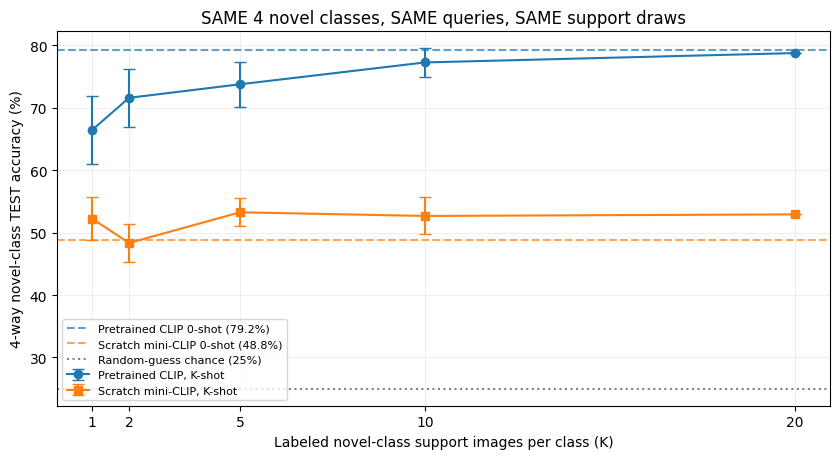

In [ ]:
scratch_fewshot_df = evaluate_few_shot(
    'Scratch mini-CLIP', scratch_support_z, scratch_support_y, scratch_query_z, query_labels
)
scratch_summary = (scratch_fewshot_df.groupby('Shots/class')['Accuracy (%)']
                   .agg(['mean', 'std']).reset_index())

combined = pd.merge(
    pretrained_summary.rename(columns={'mean':'Pretrained mean (%)','std':'Pretrained std'}),
    scratch_summary.rename(columns={'mean':'Scratch mean (%)','std':'Scratch std'}),
    on='Shots/class', validate='one_to_one'
)
print('4-way UNSEEN-class zero-shot accuracy')
display(pd.DataFrame([
    {'Model':'Pretrained CLIP','Zero-shot (%)':pretrained_zero_acc},
    {'Model':'Scratch mini-CLIP','Zero-shot (%)':scratch_zero_acc},
]).round(2))
print('4-way UNSEEN-class few-shot accuracy: mean ± std over five support draws')
display(combined.round(2))

plt.figure(figsize=(8.5, 4.7))
plt.errorbar(combined['Shots/class'], combined['Pretrained mean (%)'],
             yerr=combined['Pretrained std'], marker='o', capsize=4, label='Pretrained CLIP, K-shot')
plt.errorbar(combined['Shots/class'], combined['Scratch mean (%)'],
             yerr=combined['Scratch std'], marker='s', capsize=4, label='Scratch mini-CLIP, K-shot')
plt.axhline(pretrained_zero_acc, color='C0', linestyle='--', alpha=.7,
            label=f'Pretrained CLIP 0-shot ({pretrained_zero_acc:.1f}%)')
plt.axhline(scratch_zero_acc, color='C1', linestyle='--', alpha=.7,
            label=f'Scratch mini-CLIP 0-shot ({scratch_zero_acc:.1f}%)')
plt.axhline(25, color='gray', linestyle=':', label='Random-guess chance (25%)')
plt.xticks(SHOTS); plt.xlabel('Labeled novel-class support images per class (K)')
plt.ylabel('4-way novel-class TEST accuracy (%)')
plt.title('SAME 4 novel classes, SAME queries, SAME support draws')
plt.legend(fontsize=8); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

## C8 — Visual predictions of both models on unseen classes

Below are real novel-class test images. For a query image, both models must choose among the same four labels. We display **zero-shot** predictions here to highlight the difference between large-scale language pretraining and training with only six captions.

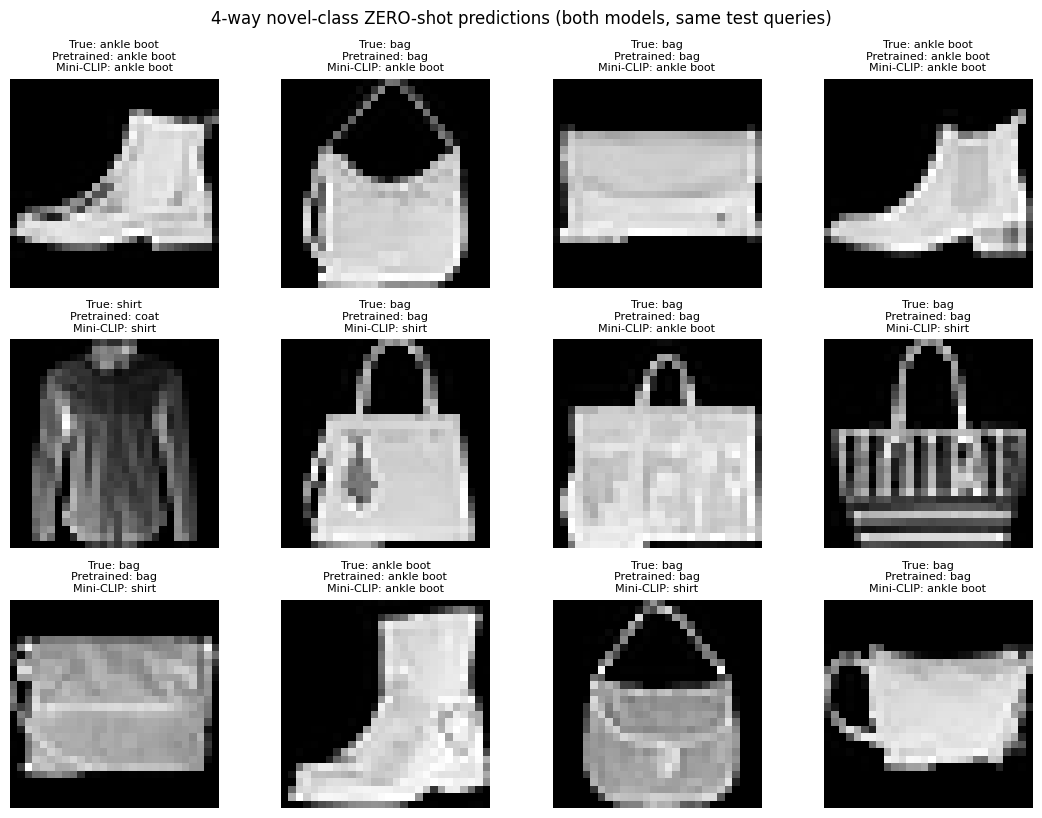

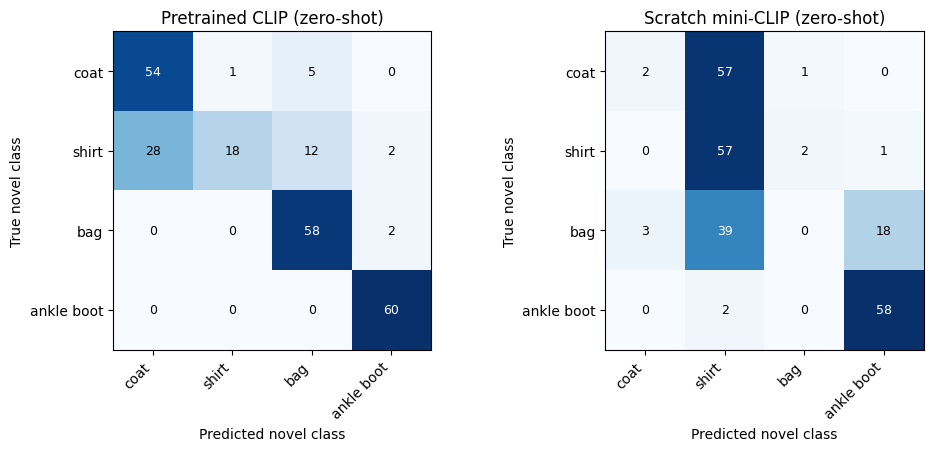

In [ ]:
fig, axs = plt.subplots(3, 4, figsize=(11, 8.3))
for ax, pos in zip(axs.ravel(), show_pos):
    truth = int(query_labels[pos]); pred_a = int(pretrained_zero_pred[pos]); pred_b = int(scratch_zero_pred[pos])
    ax.imshow(test_ds[query_indices[int(pos)]][0], cmap='gray')
    ax.set_title(f'True: {CLASS_NAMES[truth]}\nPretrained: {CLASS_NAMES[pred_a]}\nMini-CLIP: {CLASS_NAMES[pred_b]}',
                 fontsize=8)
    ax.axis('off')
plt.suptitle('4-way novel-class ZERO-shot predictions (both models, same test queries)', fontsize=12)
plt.tight_layout(); plt.show()

# Small confusion matrices: rows true novel class, columns predicted novel class.
def novel_confusion(true_global, pred_global, class_ids):
    to_local = {int(c): i for i, c in enumerate(class_ids)}
    a = np.array([to_local[int(x)] for x in true_global])
    b = np.array([to_local[int(x)] for x in pred_global])
    return np.bincount(4 * a + b, minlength=16).reshape(4, 4)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, name, pred in [(axs[0], 'Pretrained CLIP', pretrained_zero_pred),
                       (axs[1], 'Scratch mini-CLIP', scratch_zero_pred)]:
    matrix = novel_confusion(query_labels, pred, NOVEL_CLASSES)
    ax.imshow(matrix, cmap='Blues')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, int(matrix[i,j]), ha='center', va='center', fontsize=9,
                    color='white' if matrix[i,j] > matrix.max()*.60 else 'black')
    ax.set_xticks(range(4), NOVEL_CLASS_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(4), NOVEL_CLASS_NAMES)
    ax.set_xlabel('Predicted novel class'); ax.set_ylabel('True novel class')
    ax.set_title(name + ' (zero-shot)')
plt.tight_layout(); plt.show()